# Hospital Readmission analysis

Problem Statement and Objective: 

A hospital readmission is when a patient who is discharged from the hospital, gets re-admitted again within a certain period of time. Hospital readmission rates for certain conditions are now considered an indicator of hospital quality, and also affect the cost of care adversely.


For this reason, Centers for Medicare & Medicaid Services established the Hospital Readmissions Reduction Program which aims to improve quality of care for patients and reduce health care spending by applying payment penalties to hospitals that have more than expected readmission rates for certain conditions. The dataset which we will analyse is accumulation of various small dataset for patients getting readmitted within 30 days of their discharge, it is collected from diffrent hospitals consisting of standardised ICD codes for the matter of ease of documenting. Our goal is to determine factors that lead to higher readmission in such patients, and correspondingly being able to predict which patients will get readmitted can help hospitals save millions of dollars while improving quality of care.

# Dataset Description

Variable Names: Description

Encounter ID : Unique identifier of an encounter

Patient number : Unique identifier of a patient

Race Values: Caucasian, Asian, African American, Hispanic, and other

Gender Values: male, female, and unknown/invalid

Age : Grouped in 10-year intervals: 0, 10), 10, 20), …, 90, 100)

Weight : Weight in pounds

Admission type : Integer identifier corresponding to 9 distinct values, for example, emergency, urgent, elective, newborn, and not available

Discharge disposition : Integer identifier corresponding to 29 distinct values, for example, discharged to home, expired, and not available

Admission source : Integer identifier corresponding to 21 distinct values, for example, physician referral, emergency room, and transfer from a hospital

Time in hospital : Integer number of days between admission and discharge

Payer code : Integer identifier corresponding to 23 distinct values, for example, Blue Cross/Blue Shield, Medicare, and self-pay Medical

Medical specialty : Integer identifier of a specialty of the admitting physician, corresponding to 84 distinct values, for example, cardiology, internal medicine, family/general practice, and surgeon

Number of lab procedures : Number of lab tests performed during the encounter

Number of procedures : Numeric Number of procedures (other than lab tests) performed during the encounter

Number of medications : Number of distinct generic names administered during the encounter

Number of outpatient visits : Number of outpatient visits of the patient in the year preceding the encounter

Number of emergency visits : Number of emergency visits of the patient in the year preceding the encounter

Number of inpatient visits : Number of inpatient visits of the patient in the year preceding the encounter

Diagnosis 1 : The primary diagnosis (coded as first three digits of ICD9); 848 distinct values

Diagnosis 2 : Secondary diagnosis (coded as first three digits of ICD9); 923 distinct values

Diagnosis 3 : Additional secondary diagnosis (coded as first three digits of ICD9); 954 distinct values

Number of diagnoses : Number of diagnoses entered to the system 0%

Glucose serum test result : Indicates the range of the result or if the test was not taken. Values: “>200,” “>300,” “normal,” and “none” if not measured

A1c test result : Indicates the range of the result or if the test was not taken. Values: “>8” if the result was greater than 8%, “>7” if the result was greater than 7% but less than 8%, “normal” if the result was less than 7%, and “none” if not measured.

Change of medications : Indicates if there was a change in diabetic medications (either dosage or generic name). Values: “change” and “no change”

Diabetes medications : Indicates if there was any diabetic medication prescribed. Values: “yes” and “no”

24 features for medications For the generic names: metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, sitagliptin, insulin, glyburide-metformin, glipizide-metformin, glimepiride- pioglitazone, metformin-rosiglitazone, and metformin- pioglitazone, the feature indicates whether the drug was prescribed or there was a change in the dosage. Values: “up” if the dosage was increased during the encounter, “down” if the dosage was decreased, “steady” if the dosage did not change, and “no” if the drug was not prescribed

Readmitted Days to inpatient readmission. Values: “<30” if the patient was readmitted in less than 30 days, “>30” if the patient was readmitted in more than 30 days, and “No” for no record of readmission.

In [11]:
# Importing important libraries

In [12]:
import numpy as np

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
# importing warnings and ignorning unecessary ones
import warnings
warnings.filterwarnings('ignore')

In [15]:
# Importing Dataset
df = pd.read_csv(r"C:\Users\Hp\Downloads\diabetic dataset\diabetic_data.csv")

In [16]:
df.head(10).T

,0,1,2,3,4,5,6,7,8,9
encounter_id,2278392,149190,64410,500364,16680,35754,55842,63768,12522,15738
patient_nbr,8222157,55629189,86047875,82442376,42519267,82637451,84259809,114882984,48330783,63555939
race,Caucasian,Caucasian,AfricanAmerican,Caucasian,Caucasian,Caucasian,Caucasian,Caucasian,Caucasian,Caucasian
gender,Female,Female,Female,Male,Male,Male,Male,Male,Female,Female
age,[0-10),[10-20),[20-30),[30-40),[40-50),[50-60),[60-70),[70-80),[80-90),[90-100)
weight,?,?,?,?,?,?,?,?,?,?
admission_type_id,6,1,1,1,1,2,3,1,2,3
discharge_disposition_id,25,1,1,1,1,1,1,1,1,3
admission_source_id,1,7,7,7,7,2,2,7,4,4
time_in_hospital,1,3,2,2,1,3,4,5,13,12


In [17]:
# Checking for size and shape of the dataset
print(f'Dataframe size:',df.size,'\n')
print(f'Dataframe shape:',df.shape)

Dataframe size: 5088300 

Dataframe shape: (101766, 50)


In [18]:
# Getting datasets overview 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

The overview shows every variable or column has 0 null count, however on close pre inspection of raw file it was observed that most of the null values are appeared as '?' in the dataset. Hence will we look for varaibles having values '?'.

In [20]:
# checking for null/missing values by alrenative code
for col in df.columns:
    if df[col].dtype == 'string':
        print(col, round((df[col][df[col]=='?'].count()/df[col].size)*100,2))

race 2.23
gender 0.0
age 0.0
weight 96.86
payer_code 39.56
medical_specialty 49.08
diag_1 0.02
diag_2 0.35
diag_3 1.4
max_glu_serum 0.0
A1Cresult 0.0
metformin 0.0
repaglinide 0.0
nateglinide 0.0
chlorpropamide 0.0
glimepiride 0.0
acetohexamide 0.0
glipizide 0.0
glyburide 0.0
tolbutamide 0.0
pioglitazone 0.0
rosiglitazone 0.0
acarbose 0.0
miglitol 0.0
troglitazone 0.0
tolazamide 0.0
examide 0.0
citoglipton 0.0
insulin 0.0
glyburide-metformin 0.0
glipizide-metformin 0.0
glimepiride-pioglitazone 0.0
metformin-rosiglitazone 0.0
metformin-pioglitazone 0.0
change 0.0
diabetesMed 0.0
readmitted 0.0


Missing Value results:

The result suggest that about 97% of data is missing from the varaible named 'weight' it might be significat for a diebatic patient's health overview, but the dataset we are working with has limited extensions, Hence we decied to drop this column. The varible 'payer_code' and 'medical_specialty' does not logically have any significance to the target varible and they both has 40% and 49% of missing values respectivelty. Hence dropping these two columns. 

In [22]:
df = df.drop(['weight','payer_code','medical_specialty'], axis=1)
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses',
       'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
       'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')

Moving forward, the columns named race, gender, diag_1, diag_2, diag_3 also has missing values but these are compartively very low as we can see almost between 0-3%. These missing data would not make any major impact on the analysis. Therefore we have decided to drop these rows.

In [24]:
missing_val = set(df[(df['diag_1']=='?') & (df['diag_2']=='?') & (df['diag_3']=='?')].index)

missing_val = missing_val.union(set(df['diag_1'][df['diag_1'] == '?'].index))
missing_val = missing_val.union(set(df['diag_2'][df['diag_2'] == '?'].index))
missing_val = missing_val.union(set(df['diag_3'][df['diag_3'] == '?'].index))
missing_val = missing_val.union(set(df['race'][df['race'] == '?'].index))
missing_val = missing_val.union(set(df['gender'][df['gender'] == 'Unknown/Invalid'].index))

new_idx = list(set(df.index) - set(missing_val))
df = df.iloc[new_idx]

The dataset contains variable for number of inpatient(admissions), number of emergency visits and number of outpatient visits for a pateint in the past year. These variables suggest that howmuch the pateint used hospital/clinical services in past years. We have addeed these there to form a new variable named as service utilization. 

In [26]:
df['service_utilized'] = df['number_outpatient'] + df['number_emergency'] + df['number_inpatient']

In [27]:
# Analyzing drug variables and finding their unique values.
# The columns from metformin to metformin-pioglitazone (20-44) are all about the drugs/medication the patient is consuimg, we are tring to identify what 
# unique values does each of these columns has.

drugs = ['metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton',
       'insulin', 'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone']

for col in drugs:
    print(f'Unique values for {col}:',df[col].unique(),'\n')

'It is been observed that there are two drugs named "examide" and "citoglipton" which were never previously or currently prescribed/consumed by any patient in the entire dataset, Hence we have decided to drop these columns too, as they do not make any sense take forward'

Unique values for metformin: <StringArray>
['No', 'Steady', 'Up', 'Down']
Length: 4, dtype: str 

Unique values for repaglinide: <StringArray>
['No', 'Up', 'Steady', 'Down']
Length: 4, dtype: str 

Unique values for nateglinide: <StringArray>
['No', 'Steady', 'Down', 'Up']
Length: 4, dtype: str 

Unique values for chlorpropamide: <StringArray>
['No', 'Steady', 'Down', 'Up']
Length: 4, dtype: str 

Unique values for glimepiride: <StringArray>
['No', 'Steady', 'Down', 'Up']
Length: 4, dtype: str 

Unique values for acetohexamide: <StringArray>
['No', 'Steady']
Length: 2, dtype: str 

Unique values for glipizide: <StringArray>
['No', 'Steady', 'Up', 'Down']
Length: 4, dtype: str 

Unique values for glyburide: <StringArray>
['No', 'Steady', 'Up', 'Down']
Length: 4, dtype: str 

Unique values for tolbutamide: <StringArray>
['No', 'Steady']
Length: 2, dtype: str 

Unique values for pioglitazone: <StringArray>
['No', 'Steady', 'Up', 'Down']
Length: 4, dtype: str 

Unique values for rosiglitaz

'It is been observed that there are two drugs named "examide" and "citoglipton" which were never previously or currently prescribed/consumed by any patient in the entire dataset, Hence we have decided to drop these columns too, as they do not make any sense take forward'

In [28]:
df = df.drop(["examide","citoglipton"], axis=1)
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'num_lab_procedures', 'num_procedures',
       'num_medications', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses',
       'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted',
       'service_utilized'],
      dtype='str')

Changed medication combos: 

As mention in the description all the 23 listed drugs tells us whether there was any change in medication or not. These columns moslty have 4 values as No, steay, Up and Down, ideally only Up and Down can be considered as real valuable change. It should be noted that any change in the medication should be considered in reducing the readmission for all the hospital, therefore we will count the changes as overall medication change for each patient and name it as new variable 'med_utlixation_count' . This will help us to find the relation between number of changes along with drugs and drug combos used.

In [30]:
drugs = ['metformin', 'repaglinide', 'nateglinide',
       'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide',
       'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose',
       'miglitol', 'troglitazone', 'tolazamide', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone']

for drug in drugs:
    colname = str(drug) + 'temp'
    df[colname] = df[drug].apply(lambda x: 0 if(x=='No' or x=='Steady') else 1)
df['med_utilization_count'] = 0
for drug in drugs:
    colname = str(drug) + 'temp'
    df['med_utilization_count'] =  df['med_utilization_count'] + df[colname]
    del df[colname]

df['med_utilization_count'].value_counts()

med_utilization_count
0    71309
1    25350
2     1281
3      107
4        5
Name: count, dtype: int64

#Reframming the variables/columns

The Dataset contains various hosiptal's admission and discharge process types in the encoded integer form. By looking at each categories discription we have decided to club these types into fewer categories, although they might be having different specification but the base of begning of the process for admission or discharge is what we are considering for clubbing.
For example: categories like emergency and Urgent and Trauma centre can be mapped and unite as one as medical emergency.
For details we are importing a new file which contais ids/codes and their corresponding type/category of admission/discharge.

In [32]:
map_id = pd.read_csv(r'C:\Users\Hp\Downloads\diabetic dataset\Mapping_ids.csv', encoding='latin-1')
map_id.T

,0,1,2,3,4,5,6,7,8,9,...,57,58,59,60,61,62,63,64,65,66
admission_type_id,1,2,3,4,5,6,7,8,NaN,discharge_disposition_id,...,17,18,19,20,21,22,23,24,25,26
description,Emergency,Urgent,Elective,Newborn,Not Available,NaN,Trauma Center,Not Mapped,NaN,description,...,NaN,Transfer From Another Home Health Agency,Readmission to Same Home Health Agency,Not Mapped,Unknown/Invalid,Transfer from hospital inpt/same fac reslt in,Born inside this hospital,Born outside this hospital,Transfer from Ambulatory Surgery Center,Transfer from Hospice


In [33]:
df['admission_type_id'] = df['admission_type_id'].replace(2,1) #emergency
df['admission_type_id'] = df['admission_type_id'].replace(7,1) #emergency
df['admission_type_id'] = df['admission_type_id'].replace(6,5) #Not Mapped
df['admission_type_id'] = df['admission_type_id'].replace(8,5) #Not Mapped

In [34]:
print(map_id.iloc[1:][9:40])

   admission_type_id                                        description
10                 1                                 Discharged to home
11                 2  Discharged/transferred to another short term h...
12                 3                      Discharged/transferred to SNF
13                 4                      Discharged/transferred to ICF
14                 5  Discharged/transferred to another type of inpa...
15                 6  Discharged/transferred to home with home healt...
16                 7                                           Left AMA
17                 8  Discharged/transferred to home under care of H...
18                 9          Admitted as an inpatient to this hospital
19                10  Neonate discharged to another hospital for neo...
20                11                                            Expired
21                12  Still patient or expected to return for outpat...
22                13                                     Hospice

In [35]:
# Re-encoding these distict values into similar categories 
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(6,1) # to home
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(8,1)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(13,1)

df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(3,2) # To another hospital
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(4,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(5,2)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(30,2)

df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(15,10) # Neonate to another institutional care
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(16,10)
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(17,10)

df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(18,'other/unknown_disposition')
df['discharge_disposition_id'] = df['discharge_disposition_id'].replace(25,'other/unknown_disposition')

# Here we have excluded records where patinet was expired, and Hospice/home and Hospice/medical facility
df.drop(df[ df['discharge_disposition_id'].isin([11,13,14,19,20,21]) ].index, inplace= True )

#Checking for the remaning values and their counts
df['discharge_disposition_id'].value_counts()

discharge_disposition_id
1                            70737
2                            17496
other/unknown_disposition     4565
22                            1970
7                              592
23                             400
28                             137
10                              94
24                              48
9                               21
27                               5
12                               3
Name: count, dtype: int64

In [36]:
# values codes and types for admission source table
print(map_id.iloc[1:][40:])

      admission_type_id                                     description
41  admission_source_id                                     description
42                    1                              Physician Referral
43                    2                                 Clinic Referral
44                    3                                    HMO Referral
45                    4                        Transfer from a hospital
46                    5  Transfer from a Skilled Nursing Facility (SNF)
47                    6      Transfer from another health care facility
48                    7                                  Emergency Room
49                    8                           Court/Law Enforcement
50                    9                                   Not Available
51                   10           Transfer from critial access hospital
52                   11                                 Normal Delivery
53                   12                              Premature D

In [37]:
## Re-encoding the admission source variable 
df['admission_source_id'] = df['admission_source_id'].replace(2,1) # referal
df['admission_source_id'] = df['admission_source_id'].replace(3,1)

df['admission_source_id'] = df['admission_source_id'].replace(5,4) # transfer 
df['admission_source_id'] = df['admission_source_id'].replace(6,4)
df['admission_source_id'] = df['admission_source_id'].replace(10,4)
df['admission_source_id'] = df['admission_source_id'].replace(22,4)
df['admission_source_id'] = df['admission_source_id'].replace(25,4)

df['admission_source_id'] = df['admission_source_id'].replace(12,11) # Delivery 
df['admission_source_id'] = df['admission_source_id'].replace(14,23) # Born inside hospiatl
df['admission_source_id'] = df['admission_source_id'].replace(13,24) # Born outside hospital

df['admission_source_id'] = df['admission_source_id'].replace(15,9) # Not Mapped
df['admission_source_id'] = df['admission_source_id'].replace(17,9)
df['admission_source_id'] = df['admission_source_id'].replace(20,9)
df['admission_source_id'] = df['admission_source_id'].replace(21,9)


Categorization of Diagnosis

In the Dataset we can see for each patient every hospital has three types of Diagnosis as Primary, Secondary and Addtitional, simillarly like the admission/discharge codes these category of diagnosis is coded into 700-900 unique ICD codes, it is extremely difficult to remember a code and iterprete its type also it is far more difficult to analyze the numeric code in a visual as by default they will aggregate. Therefore, we are collapsing these codes into 9 distinct catgories in an almost similar fashion to that done in the original publication using this dataset. These 9 categories include Circulatory, Respiratory, Digestive, Diabetes, Injury, Musculoskeletal, Genitourinary, Neoplasms, and Others.

In [39]:
# Creating additional columns for diagnosis categories

df['diag1_cat'] = df['diag_1']
df['diag2_cat'] = df['diag_2']
df['diag3_cat'] = df['diag_3']

In [40]:
df.loc[df['diag_1'].str.contains('V'), ['diag1_cat']] = '0'
df.loc[df['diag_1'].str.contains('E'), ['diag1_cat']] = '0'
df.loc[df['diag_2'].str.contains('V'), ['diag2_cat']] = '0'
df.loc[df['diag_2'].str.contains('E'), ['diag2_cat']] = '0'
df.loc[df['diag_3'].str.contains('V'), ['diag3_cat']] = '0'
df.loc[df['diag_3'].str.contains('E'), ['diag3_cat']] = '0'

df['diag1_cat'] = df['diag1_cat'].replace('?', -1)
df['diag2_cat'] = df['diag2_cat'].replace('?', -1)
df['diag3_cat'] = df['diag3_cat'].replace('?', -1)

In [41]:
df['diag1_cat'] = df['diag1_cat'].astype(float)
df['diag2_cat'] = df['diag2_cat'].astype(float)
df['diag3_cat'] = df['diag3_cat'].astype(float)

In [42]:
# re-coding the diagnosis code for Primary diagnosis
for index, row in df.iterrows():
    if (row['diag1_cat'] >= 390 and row['diag1_cat'] < 460 ) or (np.floor(row['diag1_cat'])==785):
        df.loc[index, 'diag1_cat']= 1
    elif (row['diag1_cat'] >= 460 and row['diag1_cat'] < 520 ) or (np.floor(row['diag1_cat'])==786):
        df.loc[index, 'diag1_cat']= 2
    elif (row['diag1_cat'] >= 520 and row['diag1_cat'] < 580 ) or (np.floor(row['diag1_cat'])==787):
        df.loc[index, 'diag1_cat']= 3
    elif row['diag1_cat'] == 250:
        df.loc[index,'diag1_cat'] = 4
    elif row['diag1_cat'] >= 800 and row['diag1_cat'] < 1000:
        df.loc[index,'diag1_cat'] = 5
    elif row['diag1_cat'] >= 710 and row['diag1_cat'] < 740:
        df.loc[index,'diag1_cat'] = 6    
    elif (row['diag1_cat'] >= 580 and row['diag1_cat'] < 630) or (np.floor(row['diag1_cat'])==788):
        df.loc[index,'diag1_cat'] = 7
    elif row['diag1_cat'] >= 140 and row['diag1_cat'] < 240:
        df.loc[index,'diag1_cat'] = 8
    else:
        df.loc[index,'diag1_cat'] = 0 

In [43]:
# re-coding the diagnosis code for Secondary diagnosis
for index, row in df.iterrows():
    if (row['diag2_cat'] >= 390 and row['diag2_cat'] < 460 ) or (np.floor(row['diag2_cat'])==785):
        df.loc[index, 'diag2_cat']= 1
    elif (row['diag2_cat'] >= 460 and row['diag2_cat'] < 520 ) or (np.floor(row['diag2_cat'])==786):
        df.loc[index, 'diag2_cat']= 2
    elif (row['diag2_cat'] >= 520 and row['diag2_cat'] < 580 ) or (np.floor(row['diag2_cat'])==787):
        df.loc[index, 'diag2_cat']= 3
    elif row['diag2_cat'] == 250:
        df.loc[index,'diag2_cat'] = 4
    elif row['diag2_cat'] >= 800 and row['diag2_cat'] < 1000:
        df.loc[index,'diag2_cat'] = 5
    elif row['diag2_cat'] >= 710 and row['diag2_cat'] < 740:
        df.loc[index,'diag2_cat'] = 6    
    elif (row['diag2_cat'] >= 580 and row['diag2_cat'] < 630) or (np.floor(row['diag2_cat'])==788):
        df.loc[index,'diag2_cat'] = 7
    elif row['diag2_cat'] >= 140 and row['diag2_cat'] < 240:
        df.loc[index,'diag2_cat'] = 8
    else:
        df.loc[index,'diag2_cat'] = 0

In [44]:
# re-coding the diagnosis code for Additional diagnosis
for index, row in df.iterrows():
    if (row['diag3_cat'] >= 390 and row['diag3_cat'] < 460 ) or (np.floor(row['diag3_cat'])==785):
        df.loc[index, 'diag3_cat']= 1
    elif (row['diag3_cat'] >= 460 and row['diag3_cat'] < 520 ) or (np.floor(row['diag3_cat'])==786):
        df.loc[index, 'diag3_cat']= 2
    elif (row['diag3_cat'] >= 520 and row['diag3_cat'] < 580 ) or (np.floor(row['diag3_cat'])==787):
        df.loc[index, 'diag3_cat']= 3
    elif row['diag3_cat'] == 250:
        df.loc[index,'diag3_cat'] = 4
    elif row['diag3_cat'] >= 800 and row['diag3_cat'] < 1000:
        df.loc[index,'diag3_cat'] = 5
    elif row['diag3_cat'] >= 710 and row['diag3_cat'] < 740:
        df.loc[index,'diag3_cat'] = 6    
    elif (row['diag3_cat'] >= 580 and row['diag3_cat'] < 630) or (np.floor(row['diag3_cat'])==788):
        df.loc[index,'diag3_cat'] = 7
    elif row['diag3_cat'] >= 140 and row['diag3_cat'] < 240:
        df.loc[index,'diag3_cat'] = 8
    else:
        df.loc[index,'diag3_cat'] = 0

In [45]:
# Replacing distinct values with category names
diagnosis = ['diag1_cat', 'diag2_cat', 'diag3_cat']

mapping =  {
    1:'Circulatory',
    2:'Respiratory',
    3:'Digestive',
    4:'Diabetes',
    5:'Injury',
    6:'Musculoskeletal',
    7:'Genitourinary',
    8:'Neoplasms', 
    0:'Others' }

for col in diagnosis:
    df[col] = df[col].replace(mapping)

df['diag1_cat'] = df['diag1_cat'].astype('string')
df['diag2_cat'] = df['diag2_cat'].astype('string')
df['diag3_cat'] = df['diag3_cat'].astype('string')

#Checking unique values of target column and categorizing it:

Our goal was to improve hospital's efficiency by analyzing the causes of diabetic patients readmission into hospital within 30 days of previous admission. However, the target column has 3 unique values for readmission No admissions, >30 and <30 days; As the patients that does not readmitted after their previous discharge can be considered in admission after 30 days, this will simplify our target category and collapse the variable into 2 designated values. Which will be patinets admitted with 30 days(<30) and after 30 days(>30). 

In [47]:
df['readmitted'] = df['readmitted'].replace('>30',0)
df['readmitted'] = df['readmitted'].replace('<30',1)
df['readmitted'] = df['readmitted'].replace('NO',0)

# Data Visulization

Analyzing the target column "readmitted"

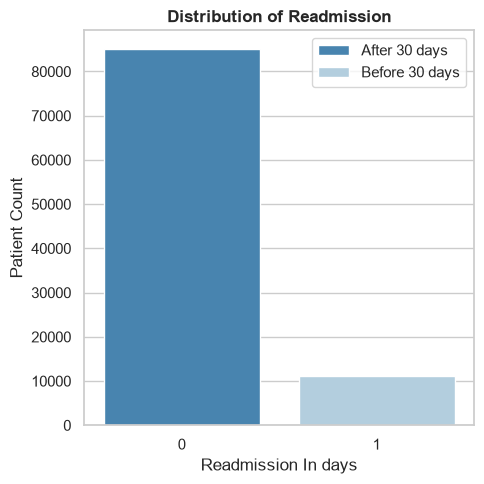

In [50]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(5,5))

ax=sns.countplot(data=df,x='readmitted',palette='Blues_r',order=df['readmitted'].value_counts().index)

plt.title('Distribution of Readmission', fontweight='bold')
ax.legend(labels=["After 30 days", "Before 30 days"])
plt.xlabel('Readmission In days')
plt.ylabel('Patient Count')

plt.tight_layout()
plt.show()

Target column appears to be highly imbalance, the readmission patients count is low compartively to readmission after 30 days. However, it is collective data of various hospitals where lower readmissions is a good sign, still readmission within 30 days is what we are amining to minimize and analyse.

# Patient's race and Readmissions

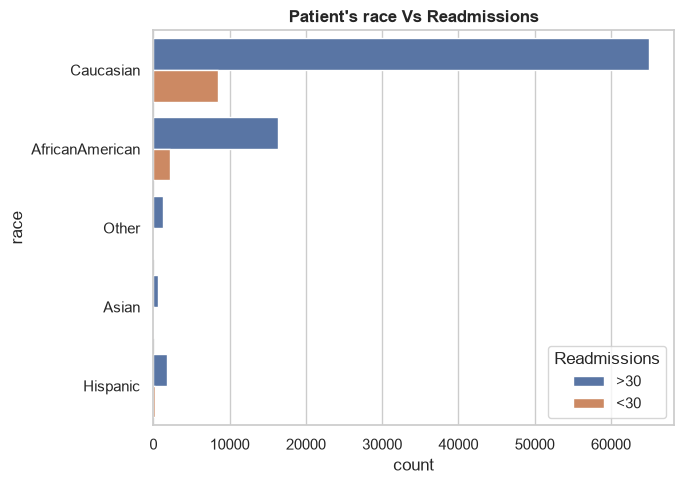

In [53]:
sns.set_theme(style ='whitegrid')

plt.figure(figsize=(7,5))

ax = sns.countplot(data=df, y='race', hue=df['readmitted'], orient='h',)
ax.legend(title="Readmissions", labels= ['>30','<30'])

plt.title("Patient's race Vs Readmissions",fontweight='bold')
plt.tight_layout()
plt.show()


The above graph clearly tells that the most readmission within 30 days of discharge are from Caucasian and African-American race. The reamission rate for after 30 days of discharge is also significantly high for both of them. If we compare these two races with others the scenario is quite opposite, they show low readmission withn 30 days and high after 30 days. Which concludes the Caucasian and African-American patinets population in the contary and their genetics should be studied. 

# Gender And Readmissions

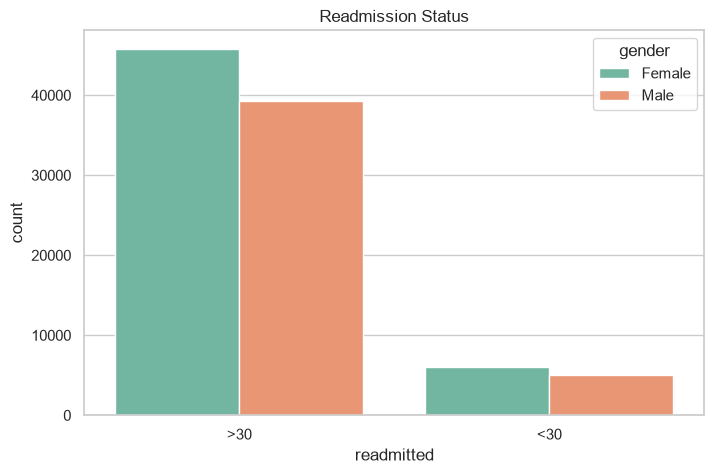

Gender Count gender
Female    51802
Male      44266
Name: count, dtype: int64


In [56]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(data=df, x='readmitted', hue='gender', palette='Set2')
plt.title("Readmission Status")
plt.xticks(ticks=[0,1], labels= ['>30','<30'])
plt.show()

print(f'Gender Count',df['gender'].value_counts())

By looking at graph we can say that the gender does not effect readmissions within 30 days, as both categories shows almost equal number of patient and similar number of readmission.

# Time Spent in Hospital and Readmissions

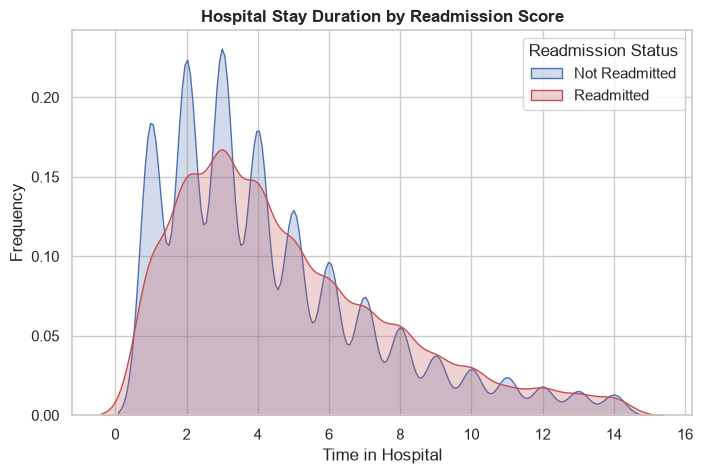

In [134]:
fig = plt.figure(figsize=(8,5))

ax=sns.kdeplot(df.loc[(df['readmitted'] == 0),'time_in_hospital'] , color='b',shade=True,label='Not Readmitted')
ax=sns.kdeplot(df.loc[(df['readmitted'] == 1),'time_in_hospital'] , color='r',shade=True,label='Readmitted')
ax.set(xlabel='Time in Hospital', ylabel='Frequency')

plt.legend(title='Readmission Status')
plt.title('Hospital Stay Duration by Readmission Score',  fontsize=12, fontweight='bold')

plt.show()

The above graph for Time and frequency of patients shows that patients who were discharged within 1 - 5 days of admission are the ones who came back in 30 days. After 5 days of treatment/discharge readmission rate continuously drop for both of its categories. Which signifies that in order to reduce the readmission rate a hospital should atleast keep its patient for more than days for observation/treatment.

# Number of medications and Readmissions

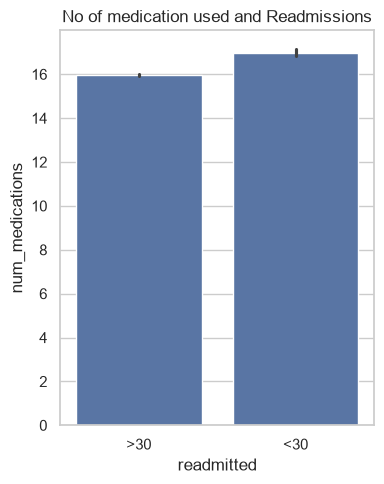

In [108]:
plt.figure(figsize=(4,5))

ax = sns.barplot(x = df['readmitted'], y = df['num_medications'])
plt.xticks(ticks=[0,1], labels=['>30','<30'])
plt.title('No of medication used and Readmissions')
plt.tight_layout()
plt.show()

Above figure shows that for more number of medicine/drug consuption count the readmission in 30 days is slightly more than after 30 days. However, the diffrence is comapretively low very and can be neglected for overview, which says medicine or drug consuption count has no effect on pateints readmission. It is more about the treatment and not the variety/Number of drugs.

# Change in Medication Vs Readmission

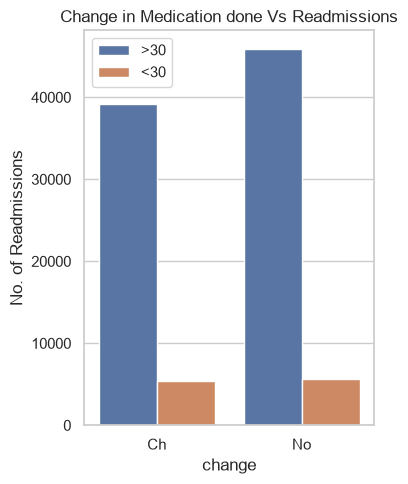

In [110]:
plt.figure(figsize=(4,5))

ax = sns.countplot( x = df['change'], hue = df['readmitted'])
ax.legend(labels=['>30','<30'])
plt.title('Change in Medication done Vs Readmissions')
plt.ylabel('No. of Readmissions')
plt.tight_layout()
plt.show()

As like the previous figure this visual tells us the same story about the readmission process, that change in the medication also do not have any role in reducing readmission rate. However, this part is concerning as the goal to change any medication is to resolve the patients health concern and ultimately it will reduce the readmissions overall. Therefore, we advise the drug suggestions should be more effective and upgraded. 

# Service utilization score and readmissions

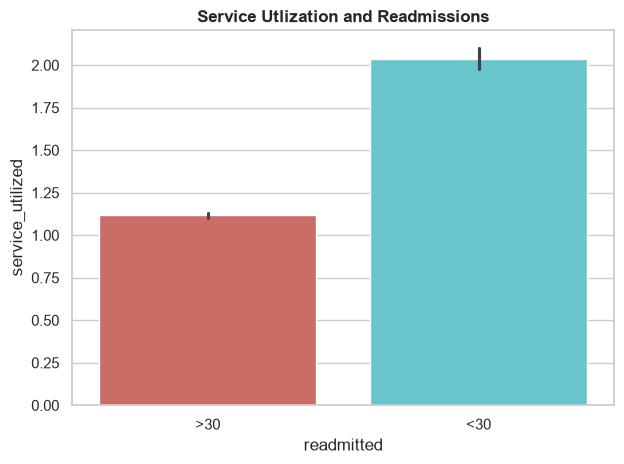

In [112]:
sns.barplot(x=df['readmitted'],y=df['service_utilized'],palette='hls')
plt.xticks(ticks=[0,1], labels=['>30','<30'])
plt.title("Service Utlization and Readmissions", fontweight="bold")
plt.tight_layout()
plt.show()

As per hospital-patinets realtionship the above visual is positive. The visual tells us patinets who has visited hospital for 2 or more times in the past year has gained trust with hospital's appointed doctors or its hospitality that they choose to readmit in the same hospital. However in case of our objective the patients previous discharge type, primary diagnosis and admission should be studied. 

# Glucose serum test and Diabetic readmission
Glucose serum test is used to find out if your blood sugar levels are in the healthy range. It also helps to help and diagnose diabetes. 
'>200' shows high glucose level,
'>300' are extremely high.

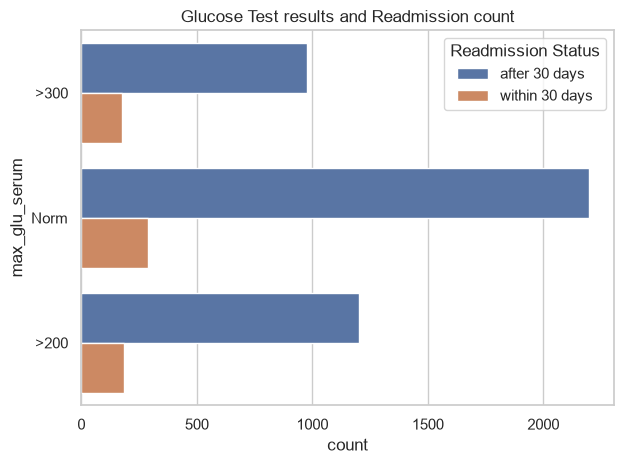

In [114]:
sns.set_theme(style = 'whitegrid')

ax= sns.countplot(y=df['max_glu_serum'],hue=df['readmitted'])
handles, labels = ax.get_legend_handles_labels()
new_legends = ['after 30 days', 'within 30 days']
plt.title('Glucose Test results and Readmission count')
ax.legend(handles= handles, labels=new_legends, title="Readmission Status")

plt.tight_layout()
plt.show()

This serum test result are quite surprising because it is undersatndable that patients with higher glucose level ">300"/">200" are revisiting hospital which we are assuming is beacuse of their Diabetes problem however pateints having Normal glucose level shows higher readmissions over other  categories in 30 days. This means that more of the patients visiting hospital on an average does not have diabetes as their primary concern.

# AC1 test results and readmissions
A1C result and Readmission A1C test - The A1C test is a blood test that provides information about your average levels of blood glucose, also called blood sugar, over the past 3 months.
'>7' : 1,
'>8' : 1,
Norm : 0 = Normal

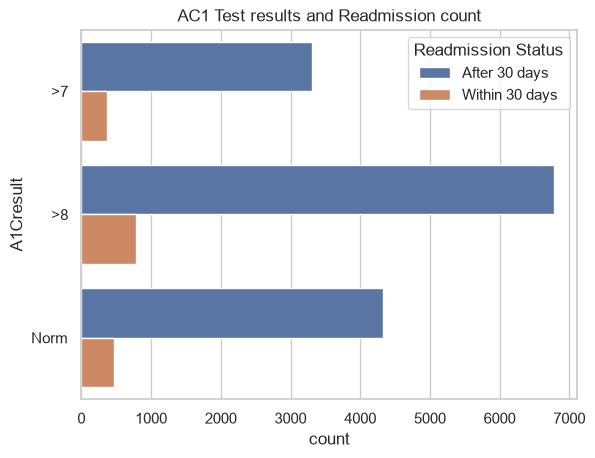

In [116]:
ax = sns.countplot(data=df, y='A1Cresult', hue='readmitted')

label_mapping = {'0': 'After 30 days', '1': 'Within 30 days'}

handles, labels = ax.get_legend_handles_labels()
new_legends = [label_mapping.get(label, label) for label in labels]

plt.title('AC1 Test results and Readmission count')
ax.legend(handles=handles, labels=new_legends, title="Readmission Status")

plt.show()

On comapring AC1 test results with Glucose serum test we can say most patients are readmitting in hospital after 30 days while having high blood sugar levels. However the dataset in its own shows biasness(imbalance) hence we are considering the within 30 days category, where we can clearly see patients overall readmitting does have problem of high bool sugar from past three months. And in case of only Glucose serum test the readmission reason contradicts completely where it shows more admissions for Normal sugar level patients. Here we can conclude, Patients readmitting in the hospital might have higher sugar levels but their reason of re-admission is very random or cannot be specified as Diabetes.

# Diagnosis type and readmission

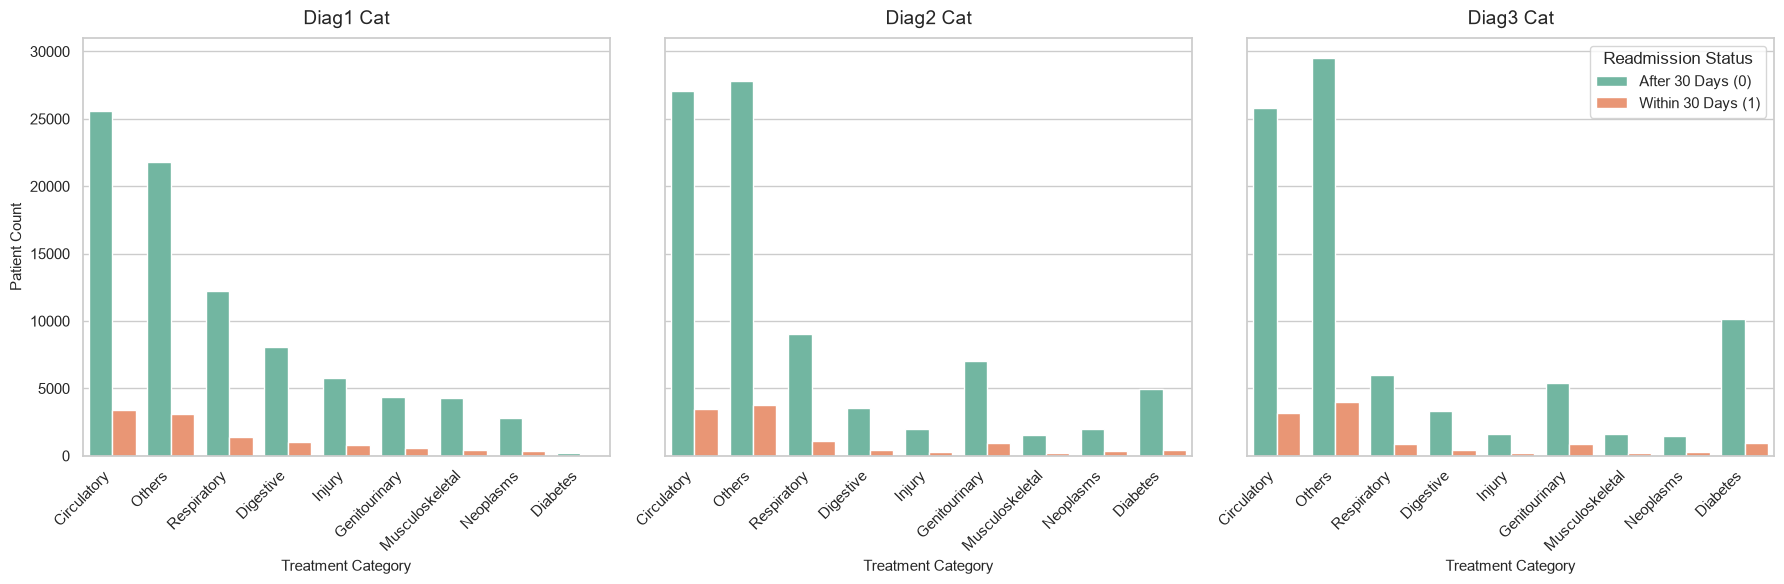

In [118]:
diagnosis_cols = ['diag1_cat', 'diag2_cat','diag3_cat']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize =(18,6), sharey=True) 
for i, col in enumerate(diagnosis_cols):
    sns.countplot(data=df, x=col, hue='readmitted', ax=axes[i], palette ='Set2', order=df['diag1_cat'].value_counts().index)

    axes[i].set_title(col.replace("_", " ").title(), fontsize=14, pad=10)
    axes[i].set_xlabel("Treatment Category", fontsize=11)
    axes[i].set_ylabel("Patient Count" if i == 0 else "", fontsize=11)

    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=45, ha="right")

    if i != 2:
        axes[i].get_legend().remove()
    else:
        axes[i].legend(
            title="Readmission Status",
            labels=["After 30 Days (0)", "Within 30 Days (1)"],
            loc="upper right",
        )

plt.tight_layout()

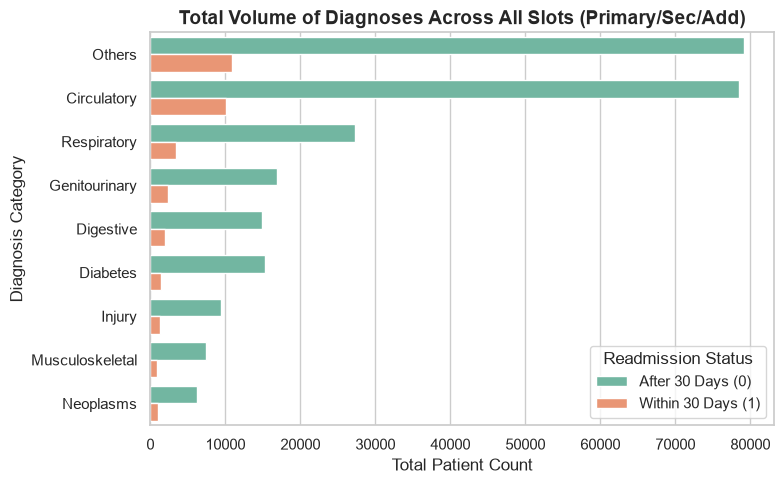

In [120]:
# Total System Burden
df_melted = pd.melt(df,id_vars=['readmitted'], value_vars=['diag1_cat', 'diag2_cat', 'diag3_cat'], var_name='Diagnosis_type', value_name='Diagnosis')

diagnosis_order = df_melted['Diagnosis'].value_counts().index
df_melted
plt.figure(figsize=(8,5))
sns.countplot(data=df_melted,y='Diagnosis', hue='readmitted', order=diagnosis_order, palette="Set2")

plt.title("Total Volume of Diagnoses Across All Slots (Primary/Sec/Add)", fontsize=14, weight="bold")
plt.xlabel("Total Patient Count")
plt.ylabel("Diagnosis Category")
plt.legend(title="Readmission Status",labels=["After 30 Days (0)", "Within 30 Days (1)"])
plt.tight_layout()
plt.show()

Lets focus on the readmission within 30 days. Above two viusal suggests the primary reason for readmission over all categories are cirulatory, others, and Respiratory. This makes the hospital's task obvious to focus on treatment of patients having these chronic diseases. Which ultimately will reduce the system burden of readmissions.

# Combination of diagnosis and readmissions

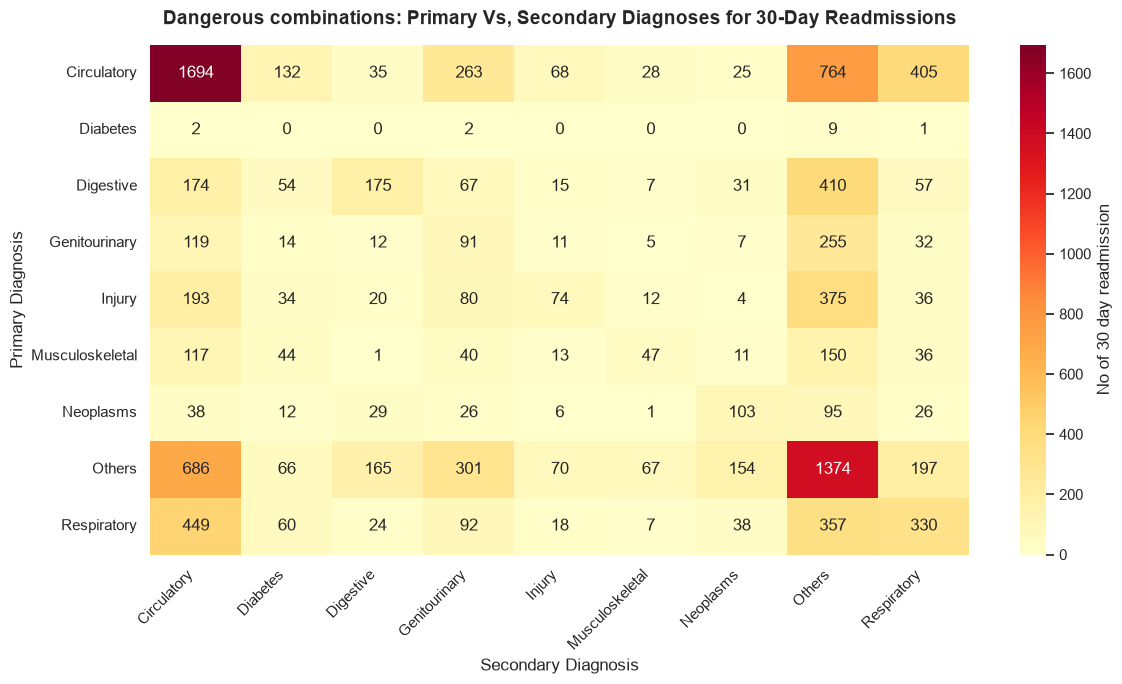

In [122]:
df_within_30 = df[df['readmitted']==1]

heatmap_data = (df_within_30.groupby(['diag1_cat','diag2_cat']).size().unstack(fill_value=0))

plt.figure(figsize=(12,7))
sns.heatmap(data= heatmap_data, annot=True, fmt='d', cmap='YlOrRd', cbar_kws = {"label":"No of 30 day readmission"})

plt.title("Dangerous combinations: Primary Vs, Secondary Diagnoses for 30-Day Readmissions", fontsize=14, weight="bold", pad=15)
plt.xlabel("Secondary Diagnosis", fontsize=12)
plt.ylabel("Primary Diagnosis", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The Single Most Dangerous Category we have found is Circulatory + Circulatory (1,698 readmissions): Patients admitted primarily for a heart/vascular issue who also have a secondary circulatory complication represent the absolute highest volume of rapid return visits.

The "Others" Complication Trap:Underlying conditions grouped into "Others" create massive readmission clusters

Respiratory Vulnerability: 
If a patient enters with a Circulatory issue but also has an underlying Respiratory issue, they bounce back heavily (405 readmissions). The inverse is also highly critical: entering with a Respiratory primary issue and a Respiratory secondary issue accounts for 330 readmissions.

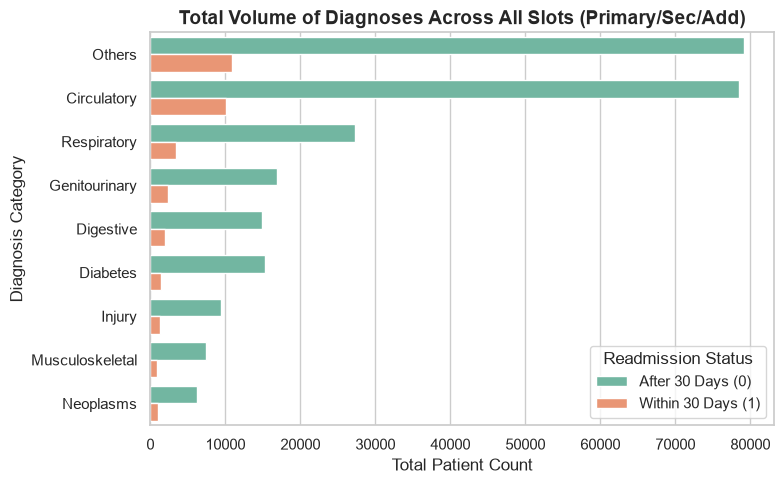

In [124]:
# Total System Burden (Ranked Horizontal Breakdown)
df_melted = pd.melt(df,id_vars=['readmitted'], value_vars=['diag1_cat', 'diag2_cat', 'diag3_cat'], var_name='Diagnosis_type', value_name='Diagnosis')

diagnosis_order = df_melted['Diagnosis'].value_counts().index
df_melted
plt.figure(figsize=(8,5))
sns.countplot(data=df_melted,y='Diagnosis', hue='readmitted', order=diagnosis_order, palette="Set2")

plt.title("Total Volume of Diagnoses Across All Slots (Primary/Sec/Add)", fontsize=14, weight="bold")
plt.xlabel("Total Patient Count")
plt.ylabel("Diagnosis Category")
plt.legend(title="Readmission Status",labels=["After 30 Days (0)", "Within 30 Days (1)"])
plt.tight_layout()
plt.show()

# Patients age and diagnosis 

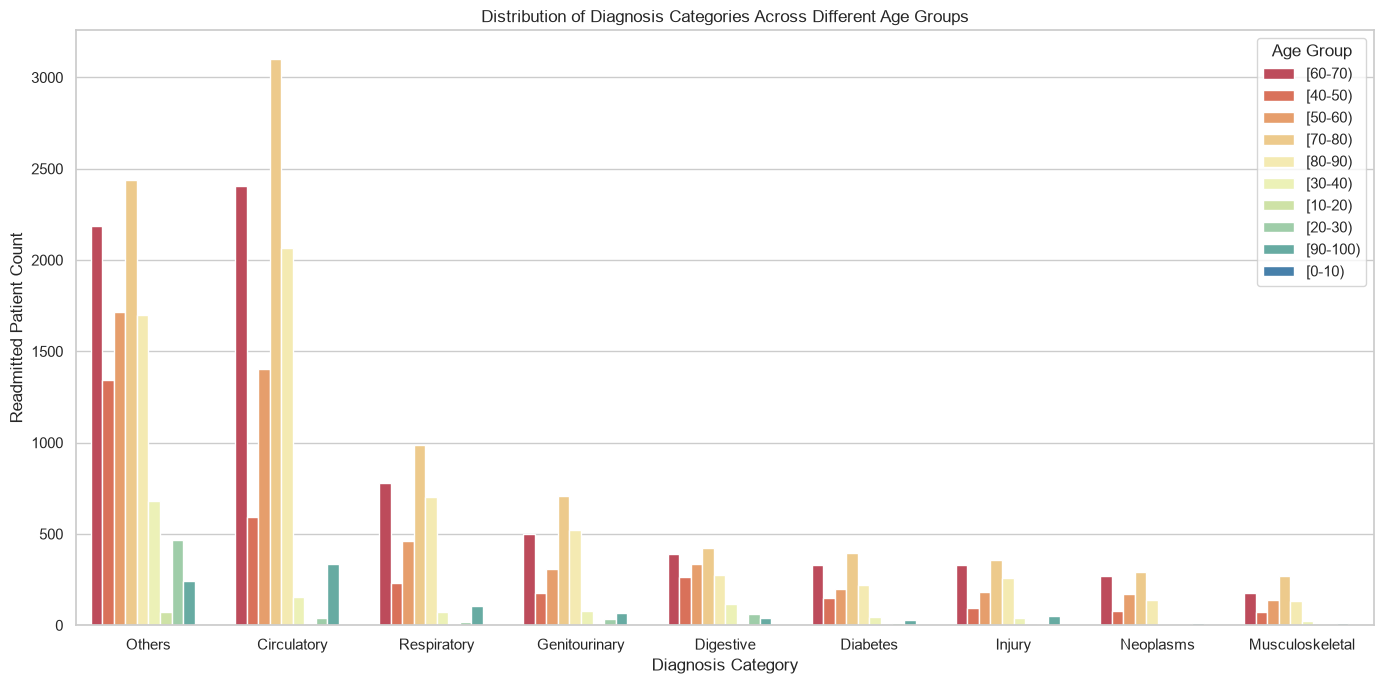

In [126]:
df_readitted = df[df["readmitted"] == 1]
df_age = pd.melt(df_readitted,id_vars=['readmitted','age'], value_vars=['diag1_cat', 'diag2_cat', 'diag3_cat'], var_name='Diagnosis_type', value_name='Diagnosis')

diagnosis_order = df_age['Diagnosis'].value_counts().index


plt.figure(figsize=(14,7))
sns.countplot(data=df_age,x='Diagnosis', hue='age', order = diagnosis_order, palette="Spectral")
plt.title("Distribution of Diagnosis Categories Across Different Age Groups")
plt.xlabel("Diagnosis Category")
plt.ylabel("Readmitted Patient Count")
plt.legend(title="Age Group")
plt.tight_layout()
plt.show()

Highly vulnareble age groups which shows major health concerns are 60-70 and 70-80. This is understandable because it is the average human age limit. 
At the age 70-80 indivudals starts to attract any chornic dieases, the category "others" clearifies it however cirulatory and respiratory also have higher probabilities. Interestingly individual living beyond 90-100 shows very less readmission.

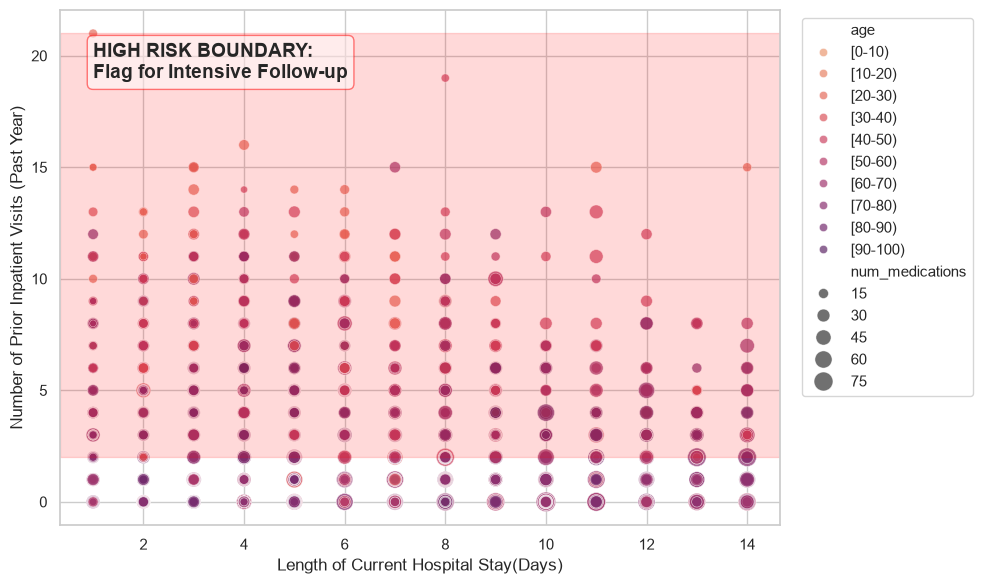

In [128]:
# The total overview

plt.figure(figsize=(10,6))
ordered_ages = sorted(df["age"].unique())
sns.scatterplot(data= df[df['readmitted']==1], x='time_in_hospital', y='number_inpatient', hue='age', hue_order= ordered_ages,
                size='num_medications', sizes=(20,200), palette='flare',alpha=0.7)

plt.axhspan(ymin=2, ymax=df['number_inpatient'].max(), color='red', alpha=0.15)
plt.text(1,19,"HIGH RISK BOUNDARY:\nFlag for Intensive Follow-up", fontsize=14, weight='bold', 
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="red", boxstyle="round"))

plt.xlabel("Length of Current Hospital Stay(Days)")
plt.ylabel("Number of Prior Inpatient Visits (Past Year)")
plt.legend(bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout()
plt.show()

1. The "Age-Driven" Stratification of the Readmission Loop
    Look at how the colors naturally separate from the bottom of the graph to the top inside the red High Risk Boundary.
    The Bottom (0 to 2 Prior Visits): This area is heavily mixed with lighter pinks and bright reds, meaning younger and middle-aged groups
    ([30-40) [40-50), [50-60)) are readmitted mostly when they have little to no prior hospital history.

    The Top (5 to 20+ Prior Visits): As you look higher into the red shaded zone, the lighter dots completely vanish. The top half is 
    strictly dominated by deep magenta and dark purple dots ([70-80), [80-90), [90-100)).
Therefore, this visually proves that extreme frequent-flyer readmissions are strictly a geriatric issue. Younger patients simply do not cross the threshold of having 5+ or 10+ admissions a year.

2. The Short-Stay "Target Clusters" are Middle-Aged to Elderly
    If we look at the columns for 2, 3, 4, and 5 days of hospital stay inside the red zone, those concentric "target circles" show 
    something fascinating when sequential. They are a dense stack of deep red and dark purple circles centered together.
This tells us that the highest volume of rapid readmissions is coming from older patients ([60-90)) who are being discharged quite rapidly
(under 5 days). The hospital may be rushing these elderly patients out the door too fast, causing them to bounce right back.

3. The Right Side Shows the Outlier "Survivors"
    Look at the far right of the graph around 12, 13, and 14 days of hospital stay: The dots at the very bottom (0 or 1 prior visits) are 
    almost completely dark purple [80-100).
This tells a very clear clinical story: if an elderly patient has no prior history of hospitalizations but is stuck in a hospital bed for two weeks, it means they suffered an incredibly severe, acute event (like a major stroke or a massive surgery). They aren't "frequent flyers," but their sheer length of stay makes them highly fragile.

Hence we can come down to 2 conclusions
1.  The Geriatric Frequent Flyers: The upper half of our red boundary is exclusively populated by dark purple dots—proving that patients with 5 to 20 prior visits are entirely elderly. They need long-term, intensive social work and chronic care coordination.*
2.  The Short-Stay Medication Clusters: The dense target circles show a massive volume of elderly patients getting discharged within 2 to 4 days with heavy medication loads (large bubble sizes). They need an immediate pharmacist or home-health nurse checkup within 48 hours of leaving to ensure they aren't mixing up their prescriptions.
